In [2]:

from sklearn.datasets import load_iris
import pandas as pd
import numpy as np

# Load Dataset
iris = load_iris()

# Convert into DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df['Target'] = iris.target

# Display first 5 rows
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:

# Dataset information
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Flower counts
print("\nFlower Type Counts:")
print(df['Target'].value_counts().sort_index())

# Statistical summary
print("\nStatistical Summary:")
df.describe()


Dataset Shape: (150, 5)

Column Names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'Target'],
      dtype='object')

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Target               0
dtype: int64

Flower Type Counts:
Target
0    50
1    50
2    50
Name: count, dtype: int64

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [4]:

from sklearn.model_selection import train_test_split

# Input features
X = df.drop('Target', axis=1)

# Output target
y = df['Target']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)


Training Data: (120, 4)
Testing Data: (30, 4)
Training Labels: (120,)
Testing Labels: (30,)


In [5]:

from sklearn.tree import DecisionTreeClassifier

# Create Machine Learning Model
model = DecisionTreeClassifier(random_state=42)

# Train the Model
model.fit(X_train, y_train)

print("Machine Learning Model Trained Successfully!")


Machine Learning Model Trained Successfully!


In [6]:

from sklearn.metrics import accuracy_score

# Predict test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")


Model Accuracy: 93.33333333333333 %


In [7]:

# New flower data
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

# Predict flower type
prediction = model.predict(new_flower)

# Display result
flower_name = iris.target_names[prediction[0]]

print("Predicted Flower:", flower_name)


Predicted Flower: setosa


In [8]:

from sklearn.metrics import confusion_matrix, classification_report

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



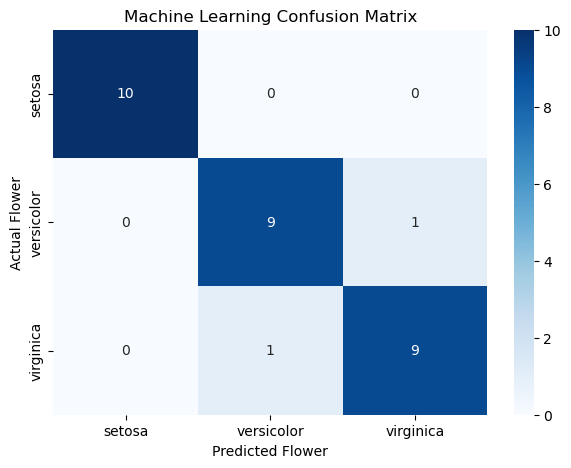

In [9]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel('Predicted Flower')
plt.ylabel('Actual Flower')
plt.title('Machine Learning Confusion Matrix')

plt.show()
